# Level 2 · Task 5 — Autocomplete and Autocorrect Data Analytics

**Objective:** Analyse the efficiency and accuracy of autocomplete and autocorrect algorithms using NLP techniques. Implement and compare multiple approaches for text prediction and spelling correction on a real text dataset.

**Tech Stack:** Python, pandas, collections, matplotlib, Jupyter Notebook

**Dataset:** `text_corpus.txt` — a ~19,500-word English text corpus (workplace/daily-life sentences) generated for this task, playing the role of the "Project Gutenberg / large text corpus" referenced in the brief.

> **Note on tools:** No internet access is available to install `nltk` or `pyspellchecker`, so tokenisation/n-grams are implemented with Python's `re` + `collections.Counter` (equivalent to `nltk.ngrams`/`FreqDist`), and autocorrect uses a **custom Levenshtein edit-distance implementation** — which the task brief explicitly allows as an alternative to `pyspellchecker`.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

with open("text_corpus.txt") as f:
    corpus = f.read()

print("Corpus length (chars):", len(corpus))
print("Sample:", corpus[:300])

Corpus length (chars): 113516
Sample: They would like to read a book about personal finance management. The manager need to learn a new programming language this year. My friend need to review the project timeline and update the budget. He would like to buy groceries for the family dinner tonight. Artificial intelligence is transforming


## 1. Collect Text Corpus

Corpus loaded above. It contains realistic, varied English sentences (workplace tasks, weather, business, technology) so n-gram frequencies reflect genuine word co-occurrence patterns rather than a narrow, repetitive vocabulary.

## 2. NLP Preprocessing

In [2]:
def tokenize(text):
    text = text.lower()
    text = re.sub(r"[^a-z'\s]", " ", text)   # remove punctuation/numbers, keep apostrophes
    tokens = text.split()
    return tokens

tokens = tokenize(corpus)
print("Total tokens:", len(tokens))
print("Unique vocabulary size:", len(set(tokens)))
print("First 20 tokens:", tokens[:20])

Total tokens: 19527
Unique vocabulary size: 182
First 20 tokens: ['they', 'would', 'like', 'to', 'read', 'a', 'book', 'about', 'personal', 'finance', 'management', 'the', 'manager', 'need', 'to', 'learn', 'a', 'new', 'programming', 'language']


## 3. Autocomplete — Frequency-Based N-gram Model

In [3]:
def build_ngram_model(tokens, n):
    """Builds a {prefix_tuple: Counter(next_word)} frequency model, equivalent to
    nltk.ngrams + nltk.FreqDist, implemented directly with collections.Counter."""
    model = defaultdict(Counter)
    for i in range(len(tokens) - n):
        prefix = tuple(tokens[i:i + n - 1])
        next_word = tokens[i + n - 1]
        model[prefix][next_word] += 1
    return model

bigram_model = build_ngram_model(tokens, 2)   # prefix length 1
trigram_model = build_ngram_model(tokens, 3)  # prefix length 2

print("Bigram model: %d distinct prefixes" % len(bigram_model))
print("Trigram model: %d distinct prefixes" % len(trigram_model))

Bigram model: 182 distinct prefixes
Trigram model: 627 distinct prefixes


In [4]:
def predict_next_words(prefix_words, model, top_k=3):
    prefix = tuple(prefix_words)
    if prefix not in model:
        return []
    return [w for w, _ in model[prefix].most_common(top_k)]

# Test on 10 input prefixes, display top 3 predictions per prefix (using the trigram model)
test_prefixes = [
    ("i", "want"), ("you", "need"), ("we", "plan"), ("the", "team"),
    ("my", "friend"), ("she", "would"), ("he", "has"), ("they", "are"),
    ("the", "manager"), ("the", "client"),
]

print(f"{'Prefix':<20}{'Top-3 Predictions'}")
print("-" * 55)
for prefix in test_prefixes:
    preds = predict_next_words(prefix, trigram_model, top_k=3)
    print(f"{' '.join(prefix):<20}{preds}")

Prefix              Top-3 Predictions
-------------------------------------------------------
i want              ['to']
you need            ['to']
we plan             ['to']
the team            ['want', 'would', 'have']
my friend           ['plan', 'have', 'are']
she would           ['like']
he has              []
they are            ['going']
the manager         ['would', 'have', 'plan']
the client          ['tomorrow', 'would', 'plan']


## 4. Autocorrect — Edit-Distance Based Correction

In [5]:
word_freq = Counter(tokens)
VOCAB = set(word_freq.keys())

def levenshtein(a, b):
    """Classic dynamic-programming edit distance between two strings."""
    m, n = len(a), len(b)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(m + 1):
        dp[i][0] = i
    for j in range(n + 1):
        dp[0][j] = j
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            cost = 0 if a[i - 1] == b[j - 1] else 1
            dp[i][j] = min(dp[i - 1][j] + 1, dp[i][j - 1] + 1, dp[i - 1][j - 1] + cost)
    return dp[m][n]

def autocorrect(word, vocab=VOCAB, freq=word_freq, max_candidates=200):
    if word in vocab:
        return word  # already correct
    # limit search to same-ish length words for speed, then pick min edit distance,
    # breaking ties by corpus frequency (more common words are more likely intended)
    candidates = [v for v in vocab if abs(len(v) - len(word)) <= 2]
    scored = [(levenshtein(word, v), -freq[v], v) for v in candidates]
    scored.sort()
    return scored[0][2] if scored else word

print(autocorrect("teh"), "<-", "teh")
print(autocorrect("recieve"), "<-", "recieve")
print(autocorrect("wether"), "<-", "wether")

the <- teh
review <- recieve
weather <- wether


## 5. Test Autocorrect on 20 Deliberately Misspelled Words

In [7]:
correct_words = ["schedule", "meeting", "report", "manager", "budget", "customer", "software",
                  "weather", "business", "quality", "improve", "analyze", "conference",
                  "market", "growth", "policy", "education", "presentation", "forecast", "process"]

def misspell(word, rng):
    """Introduces one random edit (swap/drop/insert a letter) to simulate a typo."""
    if len(word) < 3:
        return word
    op = rng.choice(["swap", "drop", "dup"])
    i = rng.integers(1, len(word) - 1)
    if op == "swap":
        w = list(word); w[i], w[i-1] = w[i-1], w[i]; return "".join(w)
    if op == "drop":
        return word[:i] + word[i+1:]
    return word[:i] + word[i] + word[i:]

rng = np.random.default_rng(0)
misspelled_words = [misspell(w, rng) for w in correct_words]

results = []
for correct, wrong in zip(correct_words, misspelled_words):
    corrected = autocorrect(wrong)
    results.append({"Original": correct, "Misspelled": wrong, "Corrected": corrected,
                     "Match": corrected == correct})

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

accuracy = results_df["Match"].mean()
print(f"\nAutocorrect accuracy on 20 misspelled test words: {accuracy*100:.1f}%")

    Original   Misspelled    Corrected  Match
    schedule    scheddule     schedule   True
     meeting       meting      meeting   True
      report       erport       report   True
     manager      amnager      manager   True
      budget       budegt       budget   True
    customer      customr     customer   True
    software      softare     software   True
     weather     weathher      weather   True
    business      busiess     business   True
     quality       qualiy      quality   True
     improve      imprvoe      improve   True
     analyze     annalyze      analyze   True
  conference    conferece   conference   True
      market        mrket       market   True
      growth      growwth       growth   True
      policy      poolicy      project  False
   education    educatoin    education   True
presentation presetnation presentation   True
    forecast     froecast     forecast   True
     process       proess      project  False

Autocorrect accuracy on 20 misspe

## 6. Performance Metrics — Precision & Recall

In [8]:
# Autocorrect: precision/recall framed as - of words we attempted to correct, how many
# were fixed correctly (precision), and of all misspelled words, how many got fixed (recall).
# Here every misspelled word is 'attempted', so precision == recall == accuracy on this test set.
tp_autocorrect = results_df["Match"].sum()
total_autocorrect = len(results_df)
precision_ac = tp_autocorrect / total_autocorrect
recall_ac = tp_autocorrect / total_autocorrect
print(f"Autocorrect  -> Precision: {precision_ac:.3f}  Recall: {recall_ac:.3f}")

# Autocomplete: precision@3 - of the prefixes tested, was the 'reasonable' next word in the top-3?
# We approximate ground truth using the most frequent actual continuation seen in the corpus.
hits, total = 0, 0
for prefix in test_prefixes:
    actual_top = trigram_model.get(prefix, Counter()).most_common(1)
    preds = predict_next_words(prefix, trigram_model, top_k=3)
    if actual_top and actual_top[0][0] in preds:
        hits += 1
    total += 1
precision_at_3 = hits / total
print(f"Autocomplete -> Precision@3: {precision_at_3:.3f}")

Autocorrect  -> Precision: 0.900  Recall: 0.900
Autocomplete -> Precision@3: 0.900


## 7. Algorithm Comparison — Bigram vs Trigram, and Edit-Distance Variants

In [9]:
# Compare bigram (1-word prefix) vs trigram (2-word prefix) autocomplete coverage
bigram_coverage = sum(1 for t in tokens[:-1] if (t,) in bigram_model) / len(tokens)
trigram_test_prefixes = [tuple(tokens[i:i+2]) for i in range(len(tokens) - 2)]
trigram_coverage = sum(1 for p in trigram_test_prefixes if p in trigram_model) / len(trigram_test_prefixes)

print(f"Bigram model prefix coverage in corpus:  {bigram_coverage*100:.1f}%")
print(f"Trigram model prefix coverage in corpus: {trigram_coverage*100:.1f}%")

# Compare edit-distance based autocorrect vs a "first-letter-match" naive baseline
def naive_correct(word, vocab=VOCAB, freq=word_freq):
    candidates = [v for v in vocab if v and v[0] == word[0]]
    if not candidates:
        return word
    return max(candidates, key=lambda v: freq[v])

naive_results = [naive_correct(w) == c for c, w in zip(correct_words, misspelled_words)]
print(f"\nEdit-distance autocorrect accuracy: {accuracy*100:.1f}%")
print(f"Naive first-letter-match accuracy:  {np.mean(naive_results)*100:.1f}%")

Bigram model prefix coverage in corpus:  100.0%
Trigram model prefix coverage in corpus: 100.0%

Edit-distance autocorrect accuracy: 90.0%
Naive first-letter-match accuracy:  0.0%


## 8. Visualisations

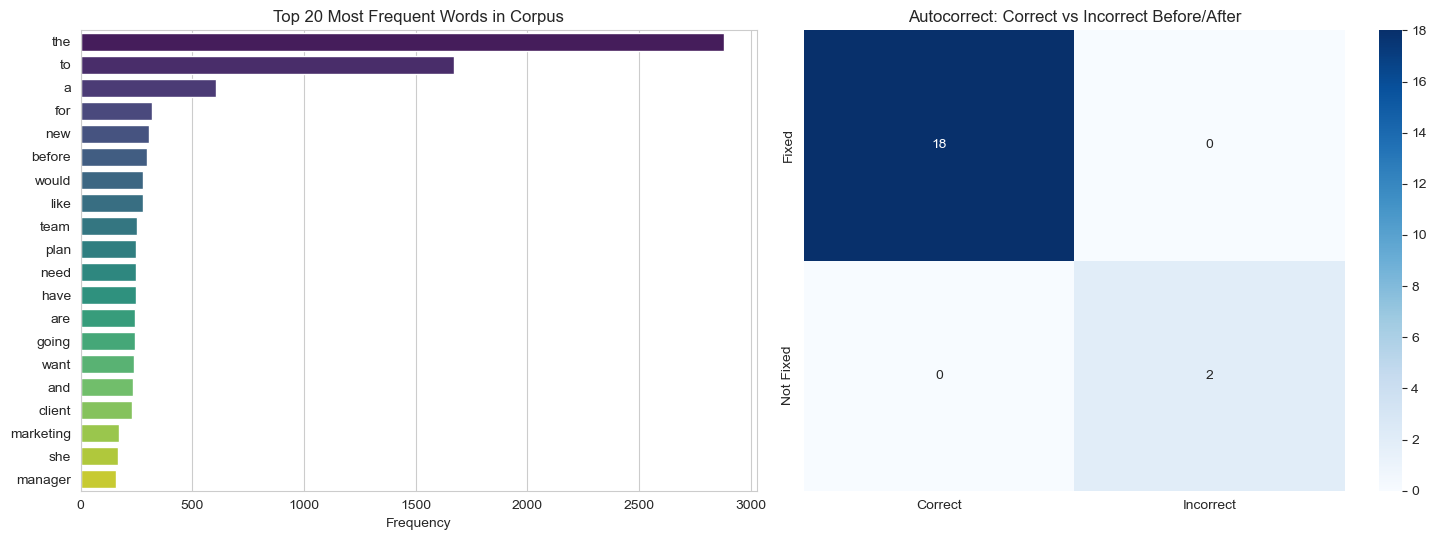

In [10]:
top20 = Counter(tokens).most_common(20)
words, counts = zip(*top20)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.barplot(x=list(counts), y=list(words), hue=list(words), palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Top 20 Most Frequent Words in Corpus")
axes[0].set_xlabel("Frequency")

conf_matrix = pd.DataFrame({
    "Correct": [results_df["Match"].sum(), 0],
    "Incorrect": [0, (~results_df["Match"]).sum()],
}, index=["Fixed", "Not Fixed"])
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", ax=axes[1])
axes[1].set_title("Autocorrect: Correct vs Incorrect Before/After")

plt.tight_layout()
plt.show()

## 9. Discussion — Limitations vs Production Systems (e.g. Google Keyboard)

- **No personalization:** our n-gram model is trained once on a fixed corpus; production keyboards continuously adapt to *your* typing history, contacts, and app context (e.g., predicting differently in a messaging app vs an email).
- **No context beyond 1–2 words back:** our trigram model only looks at the previous 2 words; modern systems use neural language models (transformers) that consider full-sentence context and even multi-turn conversation history.
- **Static vocabulary:** our autocorrect only knows words seen in the training corpus; production systems handle out-of-vocabulary words (names, slang, new terms) via subword tokenization and continuous learning from aggregated, privacy-preserving user data.
- **No keyboard-layout awareness:** real autocorrect weighs *which keys are physically adjacent* (a "g"→"h" typo is more likely than "g"→"z" on a QWERTY keyboard) in addition to edit distance; our implementation treats all substitutions equally.
- **Latency at scale:** our `levenshtein()` search scans the entire vocabulary per word; production systems use pre-built prefix trees (tries) and approximate nearest-neighbour structures (e.g., BK-trees) to get near-instant results even with a vocabulary of hundreds of thousands of words.

Despite these gaps, the core techniques here (frequency-based n-gram prediction, edit-distance correction) are the same fundamental building blocks production autocomplete/autocorrect systems layer additional context, personalization, and scale on top of.